In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
import pandas as pd
import seaborn as  sns
import time
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.cluster import contingency_matrix
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# TSNE implementation

In [ ]:
def l2_distance(X:np.array):
    sq_distances = np.sum(X**2,axis = 1)[:,None] -2*X@X.T+np.sum(X**2,axis = 1)
    return sq_distances

def poly_distance(X:np.array, degree = 1, coef0 = 0):
    return (X@(X.T)+coef0)**degree

def gaussian_distance(distance_matrix:np.array, sigmas:np.array):
    return np.exp(-distance_matrix/(2*sigmas**2))

def student_distance(y:np.array):
    #sq_distances = np.sum(y**2,axis = 1)[:,None] -2*y@y.T+np.sum(y**2,axis = 1)
    sq_distances = l2_distance(y)
    return (1+sq_distances)**(-1)


def calculate_perplexities(p):
    #υπολογίζουμε τις εντρόπιες
    h = -np.sum(p * np.log2(p), axis=1)
    #perplexity
    return (2**h)

def calculate_original_probs(X:np.array, perplexity: int, sigmas : np.array, l2_matrix: np.array):
    """"υπολογίζουμε τις αρχικές πιθανότητες, δοθέντου τις διακυμάνσεις και των πίνακα l2 αποστάσεων"""
    n,d = X.shape
    p = gaussian_distance(l2_matrix, sigmas)
    #μηδενίζουμε την διαγώνιο
    np.fill_diagonal(p, 0)
    #μικρότερη μη μηδενική τιμή
    ε  = np.nextafter(0,1)
    #υπολογισμός αθροισμάτων και broadcast και αποφυγή διαίρεσης με το 0
    sums = np.maximum(np.sum(p, axis = 1).reshape(-1,1), ε)
    p = p/sums
    #τις μηδενικές αποστάσεις τις κάνουμε ελάχιστες
    p = np.maximum(p, ε)
    return p


def calculate_mapped_joined_probs(y:np.array):
    #υπολογισμός των joined πιθανοτήτων
    q = student_distance(y)
    #q_{ii} = 0
    np.fill_diagonal(q, 0)
    #μικρότερη μη μηδενική τιμή
    ε  = np.nextafter(0,1)
    #υπολογισμός αθροισμάτων και broadcast
    sums = np.sum(q)
    q = q/sums
    #τις μηδενικές αποστάσεις τις κάνουμε ελάχιστες γιατί το q πηγαίνει στον παρονομαστή
    q = np.maximum(q, ε)
    return q

def calculate_sigmas_and_symm_original_probs(X:np.array, perplexity:int,tol:float =1e-9, attempts = 100):
    n = X.shape[0]
    distance_matrix = l2_distance(X)
    print("Euclidean Distance Matrix caclulated")
    #initialization
    sigma_maxs = np.full(n, 1e12)
    ε = np.nextafter(0,1)
    sigma_mins = np.full(n, ε)

    current_perps = np.full(n, np.inf)
    #δυαδική αναζήτηση προς εύρεση sigmas (που είναι πίνακας)
    while (not np.allclose(current_perps, perplexity, atol=tol)) and attempts > 0:
        sigmas = (sigma_mins + sigma_maxs) / 2
        p = calculate_original_probs(X, perplexity, sigmas.reshape(-1,1), distance_matrix)

        current_perps = calculate_perplexities(p)
        attempts -= 1
        for i in range(len(current_perps)):
            current_perp = current_perps[i]
            if current_perp > perplexity:
                sigma_maxs[i] = sigmas[i]
            elif current_perp < perplexity:
                sigma_mins[i] = sigmas[i]
    print("Sigmas found")
    #υπολογισμός συμμετρικών πιθανοτήτων
    p_symmetric = (p + p.T)/(2*n)
    #μικρότερη μη μηδενική τιμή
    ε = np.nextafter(0, 1)
    p_symmetric = np.maximum(p_symmetric, ε)
    return(p_symmetric)

def calculate_gradient(p, q, y):
    #πλήθος δειγμάτων
    n = y.shape[0]
    #gradient
    c = np.zeros_like(y)
    for i in range(n):
        distance = (1+np.linalg.norm(y[i]-y, axis = 1)**2)**(-1)
        weight = (p[i,:] - q[i,:])
        total_w = (distance*weight).reshape(-1,1)
        c[i,:] = 4*np.sum(total_w*(y[i] - y), axis = 0)
    return c

In [ ]:
class TSNE():
    def __init__(self, dimensions, perplexity, iterations = 1000, tol = 1e-8, verbose = True, early_exaggeration = 4, h = 100, random_state = 171):
        self.dimensions = dimensions
        self.perplexity = perplexity
        self.iterations = iterations
        self.tol = tol
        self.h = h
        self.verbose = verbose
        self.early_exaggeration = early_exaggeration
        self.random_state = random_state

    def fit_transform(self,X):
        n = X.shape[0]
        projections = np.zeros(shape=(self.iterations, n, self.dimensions))
        projections[0] = np.zeros((n, self.dimensions))
        np.random.seed(self.random_state)
        projections[1] = np.random.normal(loc = 0, scale = 1e-2, size = (n,self.dimensions))
        p_symm = calculate_sigmas_and_symm_original_probs(X, self.perplexity)
        show_cost_it = divmod(self.iterations, 10)[0]
        for i in range(1, self.iterations-1):
            if i<250:
                a = 0.5
                self.early_exaggeration = self.early_exaggeration
            else:
                a = 0.8
                self.early_exaggeration = 1
            q = calculate_mapped_joined_probs(projections[i])
            gradient = calculate_gradient(self.early_exaggeration * p_symm, q, projections[i])
            projections[i+1] = projections[i] - self.h*gradient+a*(projections[i] - projections[i-1])
            if (i % show_cost_it == 0) and self.verbose:
                #εμφάνιση κόστους
                kl_div = np.sum(p_symm * np.log(p_symm / q))
                print(f"Iteration {i}, KL(P|Q) = {kl_div}")
        #τελική συνάρτηση κόστους
        self.kl_divergence_ = np.sum(p_symm * np.log(p_symm/q))
        #επιστροφή των απεικονίσεων
        return projections[-1]

## Εφαρμογή σε δύο Dataset

### Breast Cancer Data (Kaggle)

In [ ]:
cancer_data_df = pd.read_csv("breast-cancer.csv")
cancer_data_df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
#μετατροπή σε αριθμητική της εξαρτημένης μεταβλητής
cancer_data = cancer_data_df.values
y_cancer = np.where(cancer_data[:,1]=="B", 0 ,1)
X_cancer = cancer_data[:,2:].astype(float)

<Axes: xlabel='diagnosis', ylabel='count'>

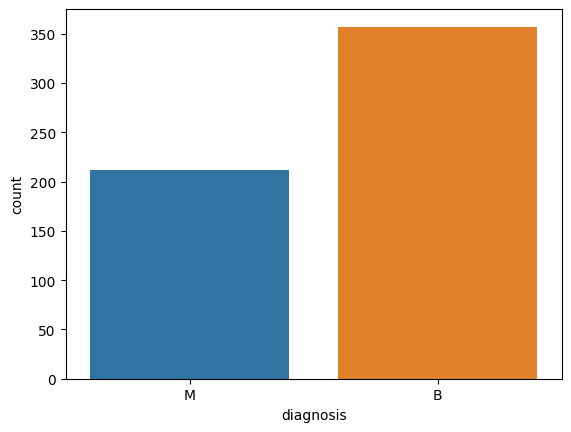

In [ ]:
#ιστόγραμμα κλάσεων
sns.countplot(data = cancer_data_df, x = "diagnosis", hue = "diagnosis")

Euclidean Distance Matrix caclulated
Sigmas found
Iteration 100, KL(P|Q) = 1.634464654555991
Iteration 200, KL(P|Q) = 1.489652158984958
Iteration 300, KL(P|Q) = 0.863384376326804
Iteration 400, KL(P|Q) = 0.685638284475602
Iteration 500, KL(P|Q) = 0.6191408411948144
Iteration 600, KL(P|Q) = 0.5818386712130849
Iteration 700, KL(P|Q) = 0.557297637630823
Iteration 800, KL(P|Q) = 0.5396543997109418
Iteration 900, KL(P|Q) = 0.5262217222129898
Perplexity 10: Process completed in 74.890 seconds
Euclidean Distance Matrix caclulated
Sigmas found
Iteration 100, KL(P|Q) = 1.2599364723102389
Iteration 200, KL(P|Q) = 1.1979505743428052
Iteration 300, KL(P|Q) = 0.6303884970236165
Iteration 400, KL(P|Q) = 0.49320603766047755
Iteration 500, KL(P|Q) = 0.4506276345216824
Iteration 600, KL(P|Q) = 0.42828440143696506
Iteration 700, KL(P|Q) = 0.414063212087143
Iteration 800, KL(P|Q) = 0.4040395015629426
Iteration 900, KL(P|Q) = 0.39650419141788423
Perplexity 20: Process completed in 73.405 seconds
Euclidean

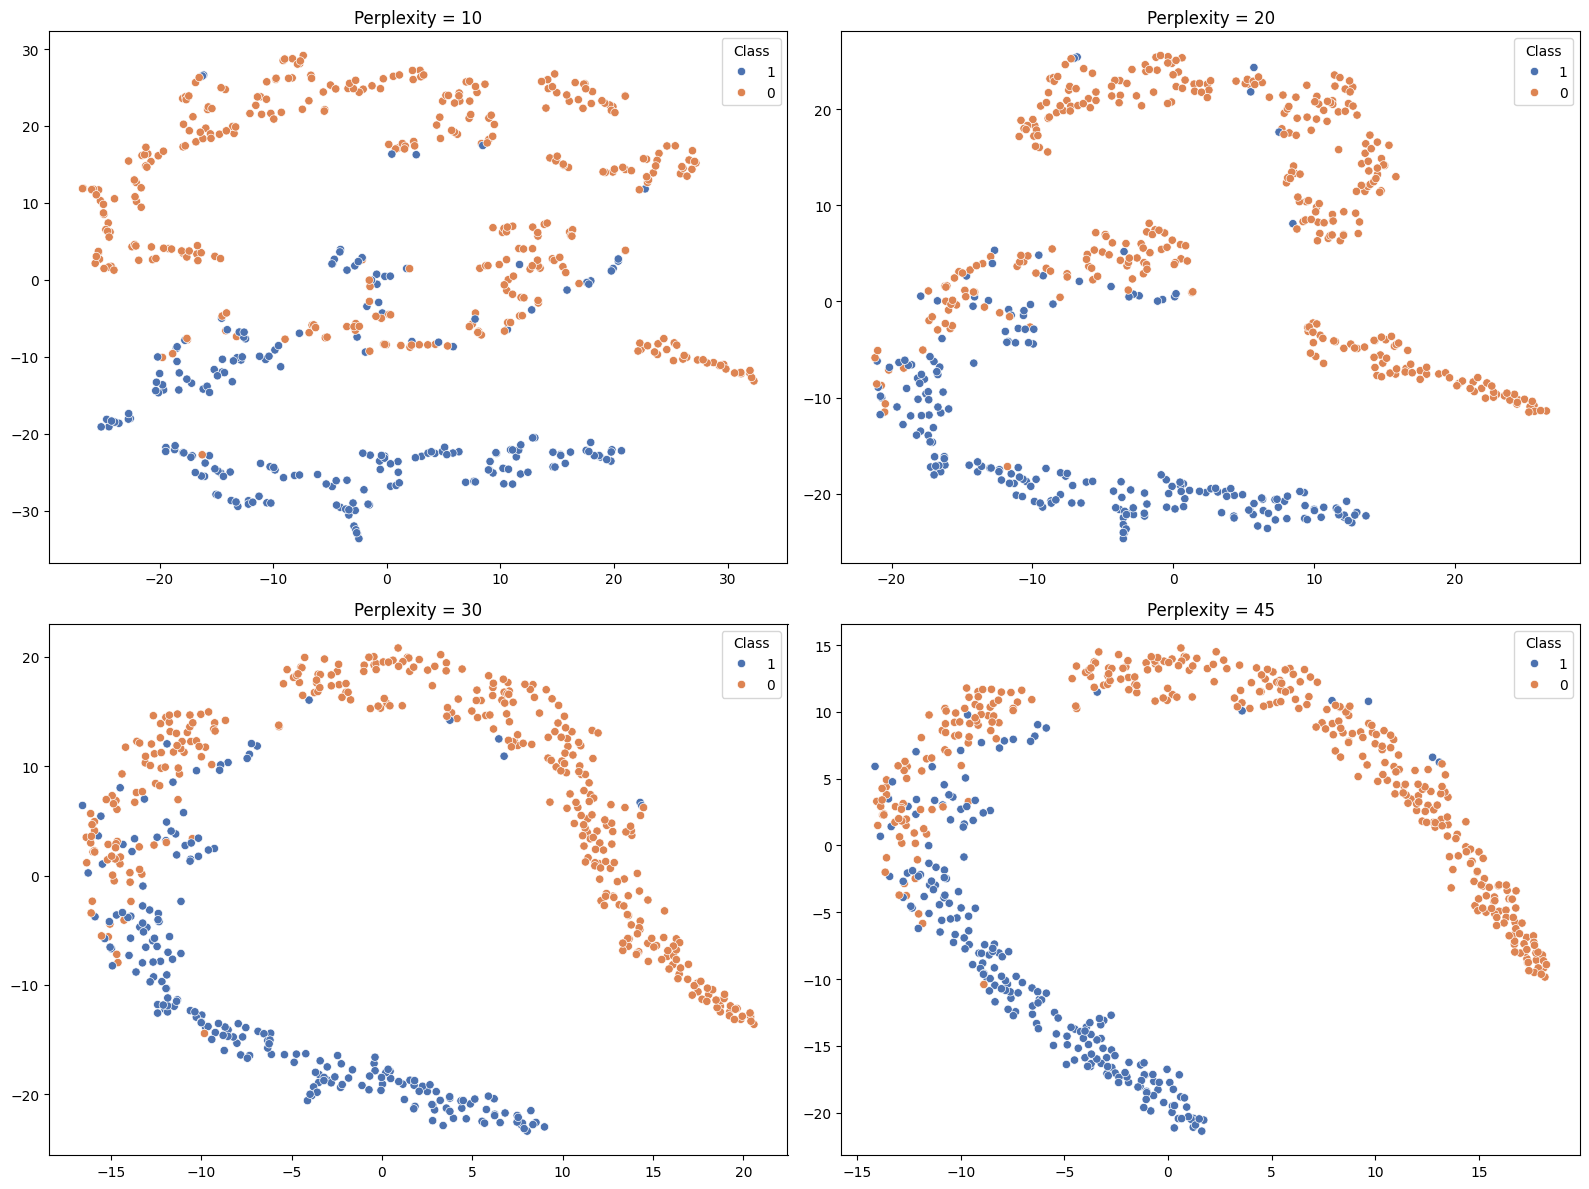

In [ ]:
perplexities = [10, 20, 30 ,45]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
times = []
axes_flat = axes.flatten()

for idx, (perp, ax) in enumerate(zip(perplexities, axes_flat)):
    #μετατροπή απο tsne
    tsne = TSNE(dimensions=2, perplexity=perp, iterations=1000)
    start = time.time()
    X_2d_cancer = tsne.fit_transform(X_cancer)
    end = time.time()

    #εμφάνιση χρόνου μετατροπής
    print(f"Perplexity {perp}: Process completed in {end - start:.3f} seconds")
    times.append(end-start)

    # Create scatter plot
    sns.scatterplot(x=X_2d_cancer[:, 0], y=X_2d_cancer[:, 1],
                   hue=y_cancer.astype(str),
                   ax=ax,
                   palette='deep')

    # Add title and clean up legend
    ax.set_title(f'Perplexity = {perp}')
    ax.legend(title='Class')
plt.tight_layout()
plt.show()
fig.savefig("breast_cancer_perps.png")

In [ ]:
tsne = TSNE(dimensions=2, perplexity=45, iterations=1500)
X_2d_cancer = tsne.fit_transform(X_cancer)

Euclidean Distance Matrix caclulated
Sigmas found
Iteration 150, KL(P|Q) = 0.8428534217716079
Iteration 300, KL(P|Q) = 0.3407343289034477
Iteration 450, KL(P|Q) = 0.24430423897675363
Iteration 600, KL(P|Q) = 0.22764040553252235
Iteration 750, KL(P|Q) = 0.22075761881746014
Iteration 900, KL(P|Q) = 0.21711939721380166
Iteration 1050, KL(P|Q) = 0.21485042436355525
Iteration 1200, KL(P|Q) = 0.21325752388692915
Iteration 1350, KL(P|Q) = 0.21204444395849603


### MNIST

In [ ]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

X = np.concatenate((X_train, X_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0)
X_flattened = X.reshape(X.shape[0], -1)
X_normalized = X_flattened.astype('float32') / 255.0
subset_indices = np.random.choice(X_normalized.shape[0], size=2000, replace=False)
X_subset = X_normalized[subset_indices]
y_subset = y[subset_indices]

Euclidean Distance Matrix caclulated
Sigmas found
Iteration 100, KL(P|Q) = 3.159024196120481
Iteration 200, KL(P|Q) = 2.9832631010368096
Iteration 300, KL(P|Q) = 2.2503470263788836
Iteration 400, KL(P|Q) = 1.8988376781062086
Iteration 500, KL(P|Q) = 1.7494327010829132
Iteration 600, KL(P|Q) = 1.6585616554919382
Iteration 700, KL(P|Q) = 1.5950991360827858
Iteration 800, KL(P|Q) = 1.5471378579627142
Iteration 900, KL(P|Q) = 1.5092099282537927
Perplexity 20: Process completed in 707.912 seconds
Euclidean Distance Matrix caclulated
Sigmas found
Iteration 100, KL(P|Q) = 3.0457960613842037
Iteration 200, KL(P|Q) = 2.898121148612221
Iteration 300, KL(P|Q) = 2.1206836319916844
Iteration 400, KL(P|Q) = 1.7855995985623185
Iteration 500, KL(P|Q) = 1.6474111208716917
Iteration 600, KL(P|Q) = 1.5640058504680734
Iteration 700, KL(P|Q) = 1.5064729944554902
Iteration 800, KL(P|Q) = 1.463483968570271
Iteration 900, KL(P|Q) = 1.429584891390112
Perplexity 25: Process completed in 744.419 seconds
Euclidea

AttributeError: 'Figure' object has no attribute 'save'

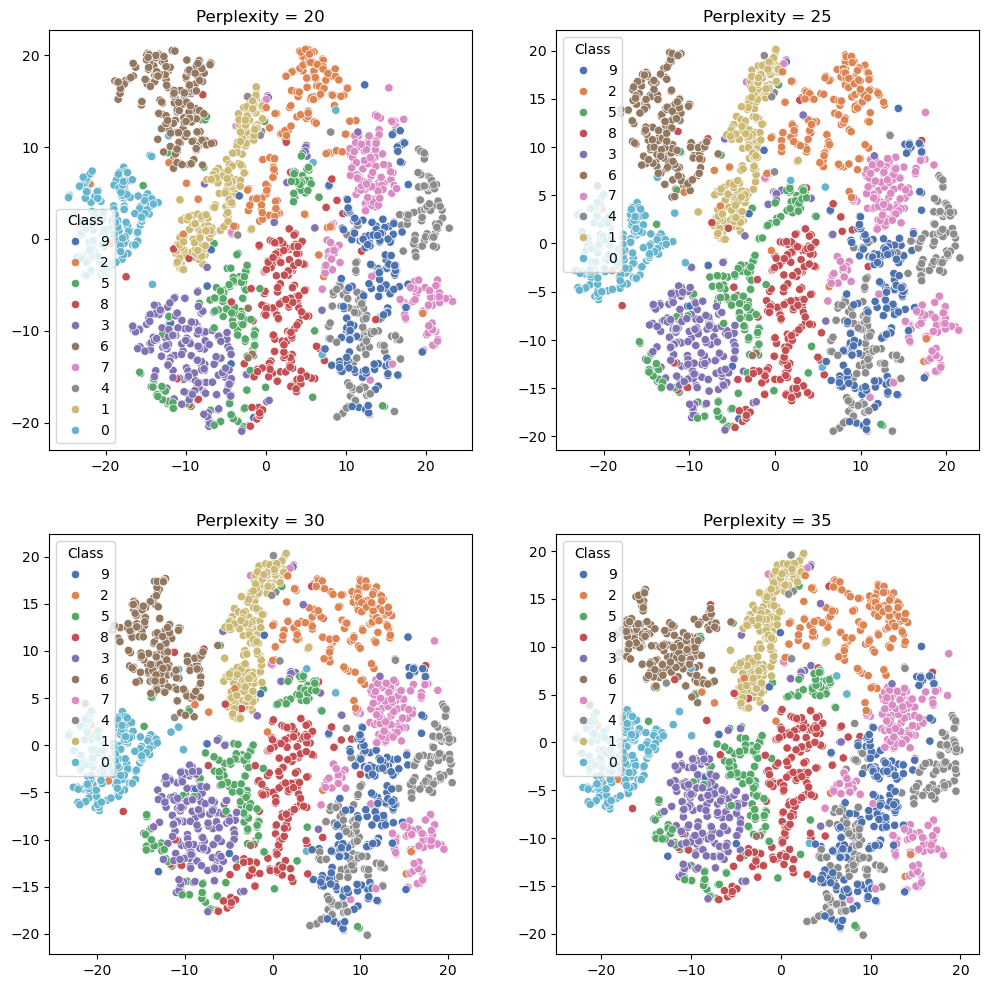

In [ ]:
perplexities = [20, 25, 30, 35]
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
times = []
axes_flat = axes.flatten()

for idx, (perp, ax) in enumerate(zip(perplexities, axes_flat)):
    #μετατροπή απο tsne
    tsne = TSNE(dimensions=2, perplexity=perp, iterations=1000)
    start = time.time()
    X_2d_mnist = tsne.fit_transform(X_subset)
    end = time.time()

    #εφμάνιση χρόνου μετατροπής
    print(f"Perplexity {perp}: Process completed in {end - start:.3f} seconds")
    times.append(end-start)

    # Create scatter plot
    sns.scatterplot(x=X_2d_mnist[:, 0], y=X_2d_mnist[:, 1],
                   hue=y_subset.astype(str),
                   ax=ax,
                   palette='deep')

    # Add title and clean up legend
    ax.set_title(f'Perplexity = {perp}')
    ax.legend(title='Class')

In [ ]:
fig.savefig("mnist_perps.png")
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

# Spectral Clustering

In [ ]:
def Kernel(X,Y, degree = 1, sigma = None, coef = 0):
    #rbf kernel
    if degree == np.inf:
        if (Y.ndim>1):
            sq_dist = np.sum(X**2,axis = 1)[:,None] -2*X@Y.T+np.sum(Y**2,axis = 1)
        else:
            sq_dist = np.linalg.norm(X, axis = 1)**2 + np.linalg.norm(Y)**2 - 2*np.dot(X, Y)
        cov = np.exp(-sq_dist/(2*sigma**2))
    elif degree > 1:
        #polynomial kernel
        if sigma is None:
            sigma = np.sqrt(1/2)
        print(degree)
        cov = ((1/(2*sigma**2))*(X@(Y.T))+coef)**degree
    else:
        #linear kernel
        cov = X@Y.T
    if ((X.ndim>1) or (Y.ndim)>1):
        return cov
    else:
        return cov.item()

#knn implementation
class KMeans:
    def __init__(self, n_clusters, max_iterations: int = 100):
        self.n_clusters = n_clusters
        self.max_iterations = max_iterations
        self.centroids = None
        self.labels = None
        self.inertia = None

    def fit(self, X: np.ndarray):

        #initialize centroids randomly
        n_samples, n_features = X.shape
        idx = np.random.choice(n_samples, self.n_clusters, replace=False)
        self.centroids = X[idx]

        for i in range(self.max_iterations):
            #assign points to nearest centroid
            old_centroids = self.centroids.copy()
            self.labels = self.assign_clusters(X)

            #update centroids
            for k in range(self.n_clusters):
                #check if cluster is empty
                if np.sum(self.labels == k) > 0:
                    self.centroids[k] = np.mean(X[self.labels == k], axis=0)

            #convergence
            if np.all(old_centroids == self.centroids):
                break

        #
        self.inertia = self.calculate_inertia(X)
        return self

    def predict(self, X: np.ndarray):
        return self.assign_clusters(X)

    def assign_clusters(self, X: np.ndarray):
        """assign each point to a cluster"""
        distances = np.sqrt(((X - self.centroids[:, np.newaxis])**2).sum(axis=2))
        return np.argmin(distances, axis=0)

    def calculate_inertia(self, X: np.ndarray):
        """sum of squared distance of each sample to each nearest centroid"""
        distances = np.sqrt(((X - self.centroids[self.labels])**2).sum(axis=1))
        return np.sum(distances**2)

In [ ]:
class Spectral_Clustering():

    def __init__(self,n_components = 2,  n_clusters = 2, degree = np.inf, kind = "unnormalized", graph = "full_connected", epsilon = 1e-3, k = 5, sigma = 1):
        self.n_clusters = n_clusters
        self.degree = degree
        self.n_components= n_components
        self.kind = kind
        self.graph = graph
        self.k = k
        self.epsilon = epsilon
        self.sigma = sigma

    def fit_predict(self, X):
        n_samples = X.shape[0]
        #calculate similarities with gaussian kernel
        W = Kernel(X = X, Y =X, degree=  self.degree, sigma= self.sigma)
        #fully connected with rbf kernel
        if self.graph  =="full_connected":
            pass
        #epsilon graph
        elif self.graph =="epsilon":
            W = np.where(W <= self.epsilon, W, 0)
        #knn graph
        else:
            l2_distances = l2_distance(X)
            neighbor_indices = np.argsort(l2_distances, axis=1)[:, 1:self.k+1]
            rows = np.repeat(np.arange(n_samples), self.k)
            cols = neighbor_indices.ravel()
            data = np.ones_like(rows, dtype=np.float32)
            W = W*csr_matrix((data, (rows, cols)), shape=(n_samples, n_samples))
            W = 0.5 * (W + W.T)

        D = np.diag(W.sum(axis=1))
        if self.kind =="unnormalized":
            #unnormalized laplacian
            L = D  - W
            #calculate eigenvectors
            eigenvalues, eigenvectors = np.linalg.eigh(L)
            #sort them
            eigenvectors = eigenvectors.real
            eigenvalues = eigenvalues.real
            idx = np.argsort(eigenvalues)
            eigenvectors = eigenvectors[:, idx]
            eigenvalues = eigenvalues[idx]

            #keep only a few (n_components)
            U = eigenvectors[:,:self.n_components]


        elif self.kind =="random walk":
            L = np.linalg.pinv(D-W)@D
            #calculate eigenvectors
            eigenvalues, eigenvectors = np.linalg.eigh(L)
            #sort them
            eigenvectors = eigenvectors.real
            eigenvalues = eigenvalues.real
            idx = np.argsort(eigenvalues)
            eigenvectors = eigenvectors[:, idx]
            eigenvalues = eigenvalues[idx]

            #keep only a few (n_components)
            U = eigenvectors[:,:self.n_components]

        else:
            ε = np.nextafter(0,1)
            D_inv_sqrt = np.diag(1.0 / np.sqrt(W.sum(axis=1)))
            D_inv_sqrt = np.maximum(D_inv_sqrt, ε)
            I = np.eye(W.shape[0])
            D_inv_sqrt_W = D_inv_sqrt @ W @ D_inv_sqrt
            L_symm = I - D_inv_sqrt_W
            #calculate the first n_components eigenvectors
            eigenvalues, eigenvectors = np.linalg.eigh(L_symm)
            #sort them
            eigenvectors = eigenvectors.real
            eigenvalues = eigenvalues.real
            idx = np.argsort(eigenvalues)
            eigenvectors = eigenvectors[:, idx]
            eigenvalues = eigenvalues[idx]

            #keep keep only a few (n_components)
            U = eigenvectors[:,:self.n_components]

            #we normalize it
            U = U/(np.linalg.norm(U,axis = 1).reshape(-1,1))

        kmeans = KMeans(n_clusters=self.n_clusters)
        kmeans.fit(U)
        labels = kmeans.predict(U)
        return labels

### Evaluation on Breast Cancer Data

In [ ]:
def get_mapped_predictions(y_pred, y_true):
    contingency = contingency_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-contingency)
    mapping = dict(zip(col_ind, row_ind))
    mapped_predictions = np.array([mapping[cluster] for cluster in y_pred])
    return mapped_predictions

           Kind           Graph  Accuracy
0  unnormalized  full_connected  0.827768
6    normalized  full_connected  0.827768
2  unnormalized             knn  0.826011
8    normalized             knn  0.826011
4   random walk         epsilon  0.813708
1  unnormalized         epsilon  0.636204
3   random walk  full_connected  0.571178
5   random walk             knn  0.543058
7    normalized         epsilon  0.543058


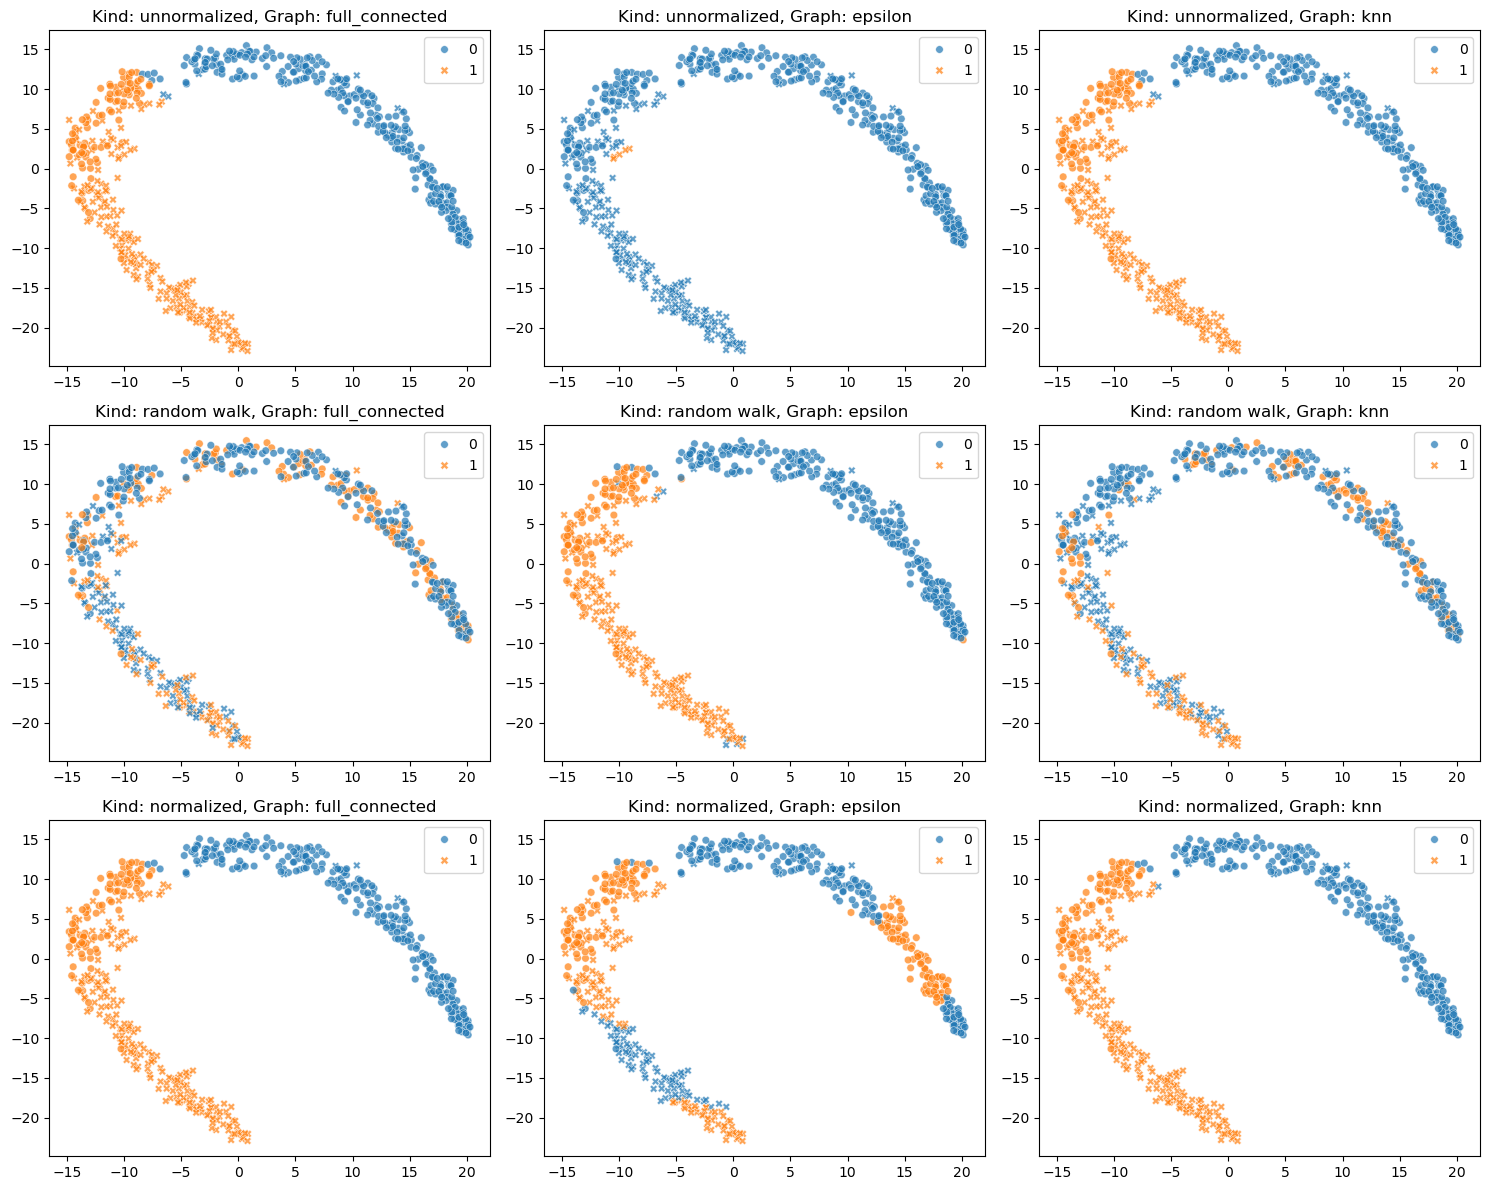

In [ ]:
scaler = StandardScaler()
X_2d_cancer_scaled = scaler.fit_transform(X_2d_cancer)

results = []
plots = []

# Define parameter combinations
kinds = ["unnormalized", "random walk", "normalized"]
graphs = ["full_connected", "epsilon", "knn"]

# Loop over parameter combinations
for kind in kinds:
    for graph in graphs:
        # Initialize and fit spectral clustering
        spectral_clustering = Spectral_Clustering(
            n_components=2,
            n_clusters=len(np.unique(y_cancer)),
            kind=kind,
            graph=graph,
            epsilon=0.05,
            k=10
        )
        y_pred = spectral_clustering.fit_predict(X_2d_cancer_scaled)
        y_mapped = get_mapped_predictions(y_pred, y_cancer)

        #accuract
        accuracy = accuracy_score(y_cancer, y_mapped)

        #store the results
        results.append({
            "Kind": kind,
            "Graph": graph,
            "Accuracy": accuracy
        })

        #append the plot
        plots.append((kind, graph, X_2d_cancer_scaled, y_mapped))

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

# Print the DataFrame
print(results_df.sort_values(by = "Accuracy", ascending  = False))

# Plot the clustering results
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for idx, (kind, graph, X, labels) in enumerate(plots):
    ax = axes[idx]
    scatter = sns.scatterplot(x = X_2d_cancer[:, 0], y = X_2d_cancer[:, 1], hue=labels, s=30, alpha=0.7, style = y_cancer, ax = ax)

    ax.set_title(f"Kind: {kind}, Graph: {graph}")

plt.tight_layout()
plt.show()

In [ ]:
fig.savefig("different_sps_cancer.png")

In [ ]:
#περαιτέρω μελέτη των συνδυασμών που έδωσαν καλύτερα αποτελέσματα
graph = "full_connected"
sigmas = [1, 1.1, 1.5, 0.5, 2]
ks  = [5, 10, 15 ,30, 50]
kind = "normalized"
results = []
plots = []
for sigma in sigmas:
    for k in ks:
        spectral_clustering = Spectral_Clustering(
            n_components=2,
            n_clusters=len(np.unique(y_cancer)),
            kind=kind,
            graph=graph,
            k=k,
            sigma = sigma
            )
        y_pred = spectral_clustering.fit_predict(X_2d_cancer_scaled)
        y_mapped = get_mapped_predictions(y_pred, y_cancer)
        accuracy = accuracy_score(y_cancer, y_mapped)
        #store the results
        results.append({"Kind": kind,"K":k,"sigma":sigma, "Accuracy": accuracy})
# Convert results to a DataFrame
results_df = pd.DataFrame(results)

# Print the DataFrame
print(results_df.sort_values(by = "Accuracy", ascending  = False))

          Kind   K  sigma  Accuracy
24  normalized  50    2.0  0.852373
23  normalized  30    2.0  0.852373
22  normalized  15    2.0  0.852373
21  normalized  10    2.0  0.852373
20  normalized   5    2.0  0.852373
10  normalized   5    1.5  0.838313
14  normalized  50    1.5  0.838313
13  normalized  30    1.5  0.838313
11  normalized  10    1.5  0.838313
12  normalized  15    1.5  0.838313
9   normalized  50    1.1  0.827768
8   normalized  30    1.1  0.827768
1   normalized  10    1.0  0.827768
7   normalized  15    1.1  0.827768
6   normalized  10    1.1  0.827768
5   normalized   5    1.1  0.827768
4   normalized  50    1.0  0.827768
3   normalized  30    1.0  0.827768
2   normalized  15    1.0  0.827768
0   normalized   5    1.0  0.827768
15  normalized   5    0.5  0.822496
16  normalized  10    0.5  0.822496
17  normalized  15    0.5  0.822496
18  normalized  30    0.5  0.822496
19  normalized  50    0.5  0.822496


### Evaluation on MNIST dataset

           Kind           Graph  Accuracy
0  unnormalized  full_connected    0.6355
8    normalized             knn    0.5835
2  unnormalized             knn    0.5605
1  unnormalized         epsilon    0.5380
6    normalized  full_connected    0.5355
7    normalized         epsilon    0.4680
4   random walk         epsilon    0.2875
3   random walk  full_connected    0.2765
5   random walk             knn    0.2720


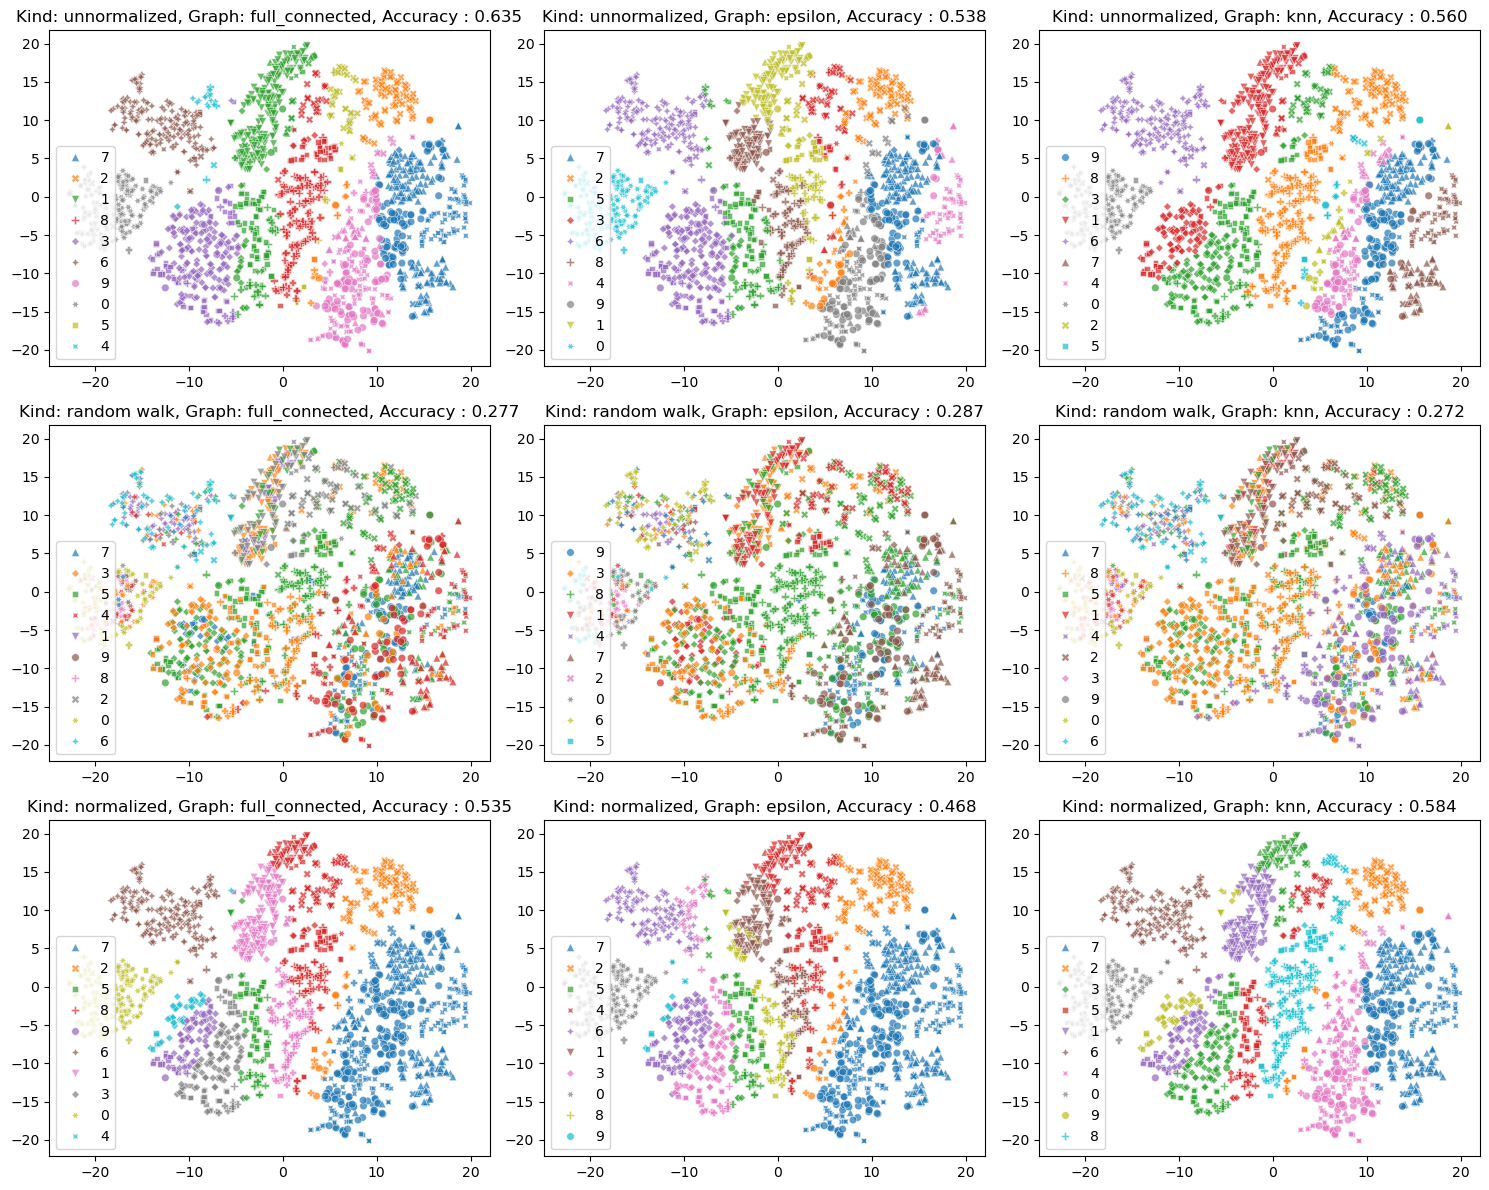

In [ ]:
results = []
plots = []

# Define parameter combinations
kinds = ["unnormalized", "random walk", "normalized"]
graphs = ["full_connected", "epsilon", "knn"]

# Loop over parameter combinations
for kind in kinds:
    for graph in graphs:
        # Initialize and fit spectral clustering
        spectral_clustering = Spectral_Clustering(
            n_components=2,
            n_clusters=len(np.unique(y_subset)),
            kind=kind,
            graph=graph,
            epsilon=0.05,
            k=5
        )
        y_pred = spectral_clustering.fit_predict(X_2d_mnist)
        y_mapped = get_mapped_predictions(y_pred, y_subset)

        #accuract
        accuracy = accuracy_score(y_subset, y_mapped)

        #store the results
        results.append({
            "Kind": kind,
            "Graph": graph,
            "Accuracy": accuracy
        })

        #append the plot
        plots.append((kind, graph, X_2d_mnist, y_mapped, accuracy))

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

# Print the DataFrame
print(results_df.sort_values(by = "Accuracy", ascending  = False))

# Plot the clustering results
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for idx, (kind, graph, X, labels, accuracy) in enumerate(plots):
    ax = axes[idx]
    scatter = sns.scatterplot(x = X_2d_mnist[:, 0], y = X_2d_mnist[:, 1], hue=labels.astype(str), s=30, alpha=0.7, style = y_subset.astype(str), ax = ax)

    ax.set_title(f"Kind: {kind}, Graph: {graph}, Accuracy : {accuracy:.3f}")

plt.tight_layout()
plt.show()

In [ ]:
fig.savefig("diff_sc_mnist.png")

In [ ]:
#περαιτέρω μελέτη των συνδυασμών που έδωσαν καλύτερα αποτελέσματα
kind = "unnormalized"
graph = "full_connected"
ks  = [20, 50, 70, 150]
sigmas = [1, 0.7, 1.1,2]
results = []
for k in ks:
    for sigma in sigmas:
        spectral_clustering = Spectral_Clustering(
            n_components=2,
            n_clusters=len(np.unique(y_subset)),
            kind=kind,
            graph=graph,
            k=k,
            sigma = sigma
            )
        y_pred = spectral_clustering.fit_predict(X_2d_mnist)
        y_mapped = get_mapped_predictions(y_pred, y_subset)
        accuracy = accuracy_score(y_subset, y_mapped)
        #store the results
        results.append({"K":k,"sigma":sigma, "Accuracy": accuracy})
# Convert results to a DataFrame
results_df = pd.DataFrame(results)

# Print the DataFrame
print(results_df.sort_values(by = "Accuracy", ascending  = False))

      K  sigma  Accuracy
4    50    1.0    0.6475
8    70    1.0    0.6475
0    20    1.0    0.6400
13  150    0.7    0.6315
5    50    0.7    0.6255
11   70    2.0    0.6040
15  150    2.0    0.6040
3    20    2.0    0.6030
1    20    0.7    0.5870
2    20    1.1    0.5800
6    50    1.1    0.5800
12  150    1.0    0.5785
7    50    2.0    0.5695
9    70    0.7    0.5525
10   70    1.1    0.5515
14  150    1.1    0.5430
